# Trust-region efficiency and accuracy across four initializations

This notebook compares the completed 000, 075, 150, and rng42 runs. It uses the latest COPT-initialized trust-region results, the matching saved CMA-ES results, and the final recorded NN-solver objective. Lower objective values are better.

The main table reports mean ± sample standard deviation across the four initializations. The convergence plot uses only the 000 run, with one best-so-far line for each iterative method and the 000 NN-solver result as a horizontal reference.

In [15]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

assert Path("results").is_dir(), "Run this notebook from the project root."


## Editable configuration

Edit METHOD_STYLE to change legend text, colors, line styles, and markers. Edit PLOT_TEXT for the title and axis labels. The file mapping is pinned to the four completed reruns so that later experiments do not silently change this analysis.

In [16]:
RUN_FILES = {
    "000": {
        "nn_history": "results/000/NN_solver_history_20260912-234954.csv",
        "zero_result": "results/000/zero_solver_result_20260913-043737.json",
        "zero_history": "results/000/zero_solver_history_20260913-043737.csv",
        "tr_result": "results/000/trust_region_result_20260924-234457.json",
    },
    "075": {
        "nn_history": "results/075/NN_solver_history_20260911-215335.csv",
        "zero_result": "results/075/zero_solver_result_20260912-135338.json",
        "zero_history": "results/075/zero_solver_history_20260912-135338.csv",
        "tr_result": "results/075/trust_region_result_20260925-035145.json",
    },
    "150": {
        "nn_history": "results/150/NN_solver_history_20260913-151813.csv",
        "zero_result": "results/150/zero_solver_result_20260913-201857.json",
        "zero_history": "results/150/zero_solver_history_20260913-201857.csv",
        "tr_result": "results/150/trust_region_result_20260925-052002.json",
    },
    "rng42": {
        "nn_history": "results/rng42/NN_solver_history_20260914-120155.csv",
        "zero_result": "results/rng42/zero_solver_result_20260914-165110.json",
        "zero_history": "results/rng42/zero_solver_history_20260914-165110.csv",
        "tr_result": "results/rng42/trust_region_result_20260925-081100.json",
    },
}
TR_BATCH_SUMMARY = Path("results/trust_region_five_runs_20260924-211815.csv")
OUTPUT_DIR = Path("plots/trust_region_four_runs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Change the label values here to revise the figure legend.
METHOD_STYLE = {
    "tr": {
        "label": "Trust region",
        "color": "tab:blue",
        "linestyle": "-",
        "linewidth": 2.6,
    },
    "zero": {
        "label": "CMA-ES",
        "color": "tab:orange",
        "linestyle": "-",
        "linewidth": 2.6,
    },
    "nn": {
        "label": "NN warm-start objective",
        "color": "tab:purple",
        "linestyle": "--",
        "linewidth": 2.0,
    },
}
PLOT_TEXT = {
    "title": "Convergence from the 000 initialization",
    "xlabel": "Cumulative composite high-fidelity queries",
    "ylabel": "Best upper-level objective",
}
LEGEND_KWARGS = {
    "loc": "best",
    "frameon": True,
    "fontsize": 14,
}
PLOT_RUN_LABEL = "000"
FIGSIZE = (8.6, 5.4)
DPI = 180


In [17]:
def read_json(path: Path) -> dict:
    with path.open("r", encoding="utf-8") as file:
        return json.load(file)


def final_nn_objective(path: Path) -> float:
    history = pd.read_csv(path)
    if history.empty or "true_loss" not in history:
        raise ValueError(f"NN history has no true_loss values: {path}")
    if "iteration" in history:
        history = history.sort_values("iteration")
    return float(history.iloc[-1]["true_loss"])


def step_curve(queries, objectives, initial_objective) -> pd.DataFrame:
    query_values = np.asarray(queries, dtype=int).reshape(-1)
    objective_values = np.asarray(objectives, dtype=float).reshape(-1)
    if len(query_values) != len(objective_values):
        raise ValueError("Query and objective arrays have different lengths.")
    query_values = np.concatenate(([0], query_values))
    objective_values = np.concatenate(([initial_objective], objective_values))
    order = np.argsort(query_values, kind="stable")
    query_values = query_values[order]
    objective_values = np.minimum.accumulate(objective_values[order])
    return pd.DataFrame(
        {"queries": query_values, "best_objective": objective_values}
    ).drop_duplicates("queries", keep="last")


for label, paths in RUN_FILES.items():
    for kind, value in paths.items():
        if not Path(value).is_file():
            raise FileNotFoundError(f"Missing {kind} for {label}: {value}")
if not TR_BATCH_SUMMARY.is_file():
    raise FileNotFoundError(TR_BATCH_SUMMARY)

batch_summary = pd.read_csv(TR_BATCH_SUMMARY)
records = []
curves = {}

for label, configured_paths in RUN_FILES.items():
    paths = {name: Path(value) for name, value in configured_paths.items()}
    nn_objective = final_nn_objective(paths["nn_history"])

    zero_result = read_json(paths["zero_result"])
    zero_history = pd.read_csv(paths["zero_history"]).sort_values("interaction")
    zero_objective = float(zero_result["optimal_value"])
    zero_queries = int(zero_result["n_interactions"])
    zero_runtime = float(zero_result["runtime_seconds"])
    zero_best_position = int(zero_history["upper_objective"].to_numpy().argmin())
    zero_best_query = int(zero_history.iloc[zero_best_position]["interaction"])
    zero_history_best = float(zero_history.iloc[zero_best_position]["upper_objective"])
    if not np.isclose(zero_history_best, zero_objective, rtol=1e-8, atol=1e-8):
        raise ValueError(
            f"CMA-ES JSON objective and history minimum disagree for {label}."
        )
    # The history has no timestamps. This is only a linear estimate based on
    # the JSON's exact total wall-clock runtime and total query count.
    zero_estimated_time_to_best = zero_runtime * zero_best_query / zero_queries

    tr_result = read_json(paths["tr_result"])
    tr_history = pd.DataFrame(tr_result["history"]).sort_values("k")
    tr_objective = float(tr_history.iloc[-1]["F_next"])
    zero_best_so_far = zero_history["upper_objective"].cummin()
    zero_reached_rows = zero_history.loc[
        zero_best_so_far <= tr_objective + 1e-12
    ]
    zero_reached_tr_target = not zero_reached_rows.empty
    if zero_reached_tr_target:
        zero_target_row = zero_reached_rows.iloc[0]
        zero_queries_to_tr_target = int(zero_target_row["interaction"])
        zero_objective_at_tr_target = float(zero_target_row["upper_objective"])
    else:
        # User-requested capped convention: record the full 9000-query
        # budget when CMA-ES never reaches the TR final objective.
        zero_queries_to_tr_target = zero_queries
        zero_objective_at_tr_target = float(zero_best_so_far.iloc[-1])
    if "cumulative_composite_queries" in tr_history:
        tr_query_axis = tr_history["cumulative_composite_queries"].to_numpy(int)
    else:
        n_samples = int(tr_result["params"]["algo_params"]["n_samples"])
        tr_query_axis = (tr_history["k"].to_numpy(int) + 1) * (n_samples + 1)
    tr_queries = int(tr_query_axis[-1])

    runtime_rows = batch_summary.loc[
        (batch_summary["label"].astype(str) == label)
        & (batch_summary["status"] == "complete")
        & (batch_summary["result_json"].astype(str) == str(paths["tr_result"])),
    ]
    if runtime_rows.empty:
        raise ValueError(
            f"No matching TR runtime in {TR_BATCH_SUMMARY} for {paths['tr_result']}."
        )
    tr_runtime = float(runtime_rows.iloc[-1]["elapsed_seconds"])

    records.append(
        {
            "initialization": label,
            "nn_objective": nn_objective,
            "zero_objective": zero_objective,
            "tr_objective": tr_objective,
            "zero_queries": zero_queries,
            "tr_queries": tr_queries,
            "zero_runtime_seconds": zero_runtime,
            "tr_runtime_seconds": tr_runtime,
            "zero_best_query": zero_best_query,
            "zero_reached_tr_target": zero_reached_tr_target,
            "zero_queries_to_tr_target": zero_queries_to_tr_target,
            "zero_objective_at_tr_target": zero_objective_at_tr_target,
            "zero_estimated_time_to_best_seconds": zero_estimated_time_to_best,
            "tr_iterations": int(tr_result["n_iter"]),
            "tr_stop_reason": tr_result.get("stop_reason"),
        }
    )
    curves[(label, "zero")] = step_curve(
        zero_history["interaction"],
        zero_history["upper_objective"],
        nn_objective,
    )
    curves[(label, "tr")] = step_curve(
        tr_query_axis,
        tr_history["F_next"],
        nn_objective,
    )

per_run = pd.DataFrame(records).set_index("initialization")
per_run["nn_gap_vs_zero_percent"] = (
    (per_run["nn_objective"] - per_run["zero_objective"])
    / per_run["zero_objective"].abs()
    * 100.0
)
per_run["tr_gap_vs_zero_percent"] = (
    (per_run["tr_objective"] - per_run["zero_objective"])
    / per_run["zero_objective"].abs()
    * 100.0
)
per_run["tr_query_reduction_percent"] = (
    1.0 - per_run["tr_queries"] / per_run["zero_queries"]
) * 100.0
per_run["tr_runtime_reduction_percent"] = (
    1.0 - per_run["tr_runtime_seconds"] / per_run["zero_runtime_seconds"]
) * 100.0
per_run["zero_runtime_hours"] = per_run["zero_runtime_seconds"] / 3600.0
per_run["tr_runtime_hours"] = per_run["tr_runtime_seconds"] / 3600.0
per_run["zero_estimated_time_to_best_hours"] = (
    per_run["zero_estimated_time_to_best_seconds"] / 3600.0
)

display(per_run)


,nn_objective,zero_objective,tr_objective,zero_queries,tr_queries,zero_runtime_seconds,tr_runtime_seconds,zero_best_query,zero_reached_tr_target,zero_queries_to_tr_target,...,zero_estimated_time_to_best_seconds,tr_iterations,tr_stop_reason,nn_gap_vs_zero_percent,tr_gap_vs_zero_percent,tr_query_reduction_percent,tr_runtime_reduction_percent,zero_runtime_hours,tr_runtime_hours,zero_estimated_time_to_best_hours
initialization,,,,,,,,,,,,,,,,,,,,,
000,-103.737458,-105.268278,-105.757233,9000,1891,15016.024904,8801.796164,8983,False,9000,...,14987.661301,31,converged,1.454208,-0.464484,78.988889,41.383980,4.171118,2.444943,4.163239
075,-98.432021,-101.265648,-100.717135,9000,3172,14051.465335,14807.607400,8989,True,4409,...,14034.291322,52,converged,2.798212,0.541658,64.755556,-5.381233,3.903185,4.113224,3.898414
150,-93.641439,-96.131815,-94.632933,9000,1220,15844.953989,5296.830953,8867,True,1407,...,15610.800780,20,converged,2.590584,1.559195,86.444444,66.570866,4.401376,1.471342,4.336334
rng42,-97.986705,-100.546388,-100.034189,9000,2257,15179.002226,10258.011713,8986,True,3887,...,15155.390445,37,converged,2.545773,0.509416,74.922222,32.419723,4.216390,2.849448,4.209831


## Efficiency–accuracy tables

The objective gap is signed: a positive value means trust region is worse than CMA-ES, while a negative value means it is better. Standard deviations use ddof=1.

In [18]:
def mean_std(values) -> tuple[float, float]:
    series = pd.Series(values, dtype=float).dropna()
    return float(series.mean()), float(series.std(ddof=1))


def formatted_mean_std(values, decimals=2, scale=1.0) -> str:
    mean, std = mean_std(pd.Series(values, dtype=float) * scale)
    return f"{mean:.{decimals}f} ± {std:.{decimals}f}"


method_numeric = pd.DataFrame(
    [
        {
            "method": "NN solver",
            "objective_mean": per_run["nn_objective"].mean(),
            "objective_std": per_run["nn_objective"].std(ddof=1),
            "queries_mean": np.nan,
            "queries_std": np.nan,
            "runtime_hours_mean": np.nan,
            "runtime_hours_std": np.nan,
            "gap_vs_zero_percent_mean": per_run["nn_gap_vs_zero_percent"].mean(),
            "gap_vs_zero_percent_std": per_run["nn_gap_vs_zero_percent"].std(ddof=1),
            "query_reduction_percent_mean": np.nan,
            "query_reduction_percent_std": np.nan,
            "runtime_reduction_percent_mean": np.nan,
            "runtime_reduction_percent_std": np.nan,
        },
        {
            "method": "CMA-ES",
            "objective_mean": per_run["zero_objective"].mean(),
            "objective_std": per_run["zero_objective"].std(ddof=1),
            "queries_mean": per_run["zero_queries"].mean(),
            "queries_std": per_run["zero_queries"].std(ddof=1),
            "runtime_hours_mean": per_run["zero_runtime_hours"].mean(),
            "runtime_hours_std": per_run["zero_runtime_hours"].std(ddof=1),
            "gap_vs_zero_percent_mean": 0.0,
            "gap_vs_zero_percent_std": 0.0,
            "query_reduction_percent_mean": 0.0,
            "query_reduction_percent_std": 0.0,
            "runtime_reduction_percent_mean": 0.0,
            "runtime_reduction_percent_std": 0.0,
        },
        {
            "method": "Trust region",
            "objective_mean": per_run["tr_objective"].mean(),
            "objective_std": per_run["tr_objective"].std(ddof=1),
            "queries_mean": per_run["tr_queries"].mean(),
            "queries_std": per_run["tr_queries"].std(ddof=1),
            "runtime_hours_mean": per_run["tr_runtime_hours"].mean(),
            "runtime_hours_std": per_run["tr_runtime_hours"].std(ddof=1),
            "gap_vs_zero_percent_mean": per_run["tr_gap_vs_zero_percent"].mean(),
            "gap_vs_zero_percent_std": per_run["tr_gap_vs_zero_percent"].std(ddof=1),
            "query_reduction_percent_mean": per_run["tr_query_reduction_percent"].mean(),
            "query_reduction_percent_std": per_run["tr_query_reduction_percent"].std(ddof=1),
            "runtime_reduction_percent_mean": per_run["tr_runtime_reduction_percent"].mean(),
            "runtime_reduction_percent_std": per_run["tr_runtime_reduction_percent"].std(ddof=1),
        },
    ]
).set_index("method")

publication_table = pd.DataFrame(
    {
        "Final objective ↓": [
            f"{row.objective_mean:.2f} ± {row.objective_std:.2f}"
            for row in method_numeric.itertuples()
        ],
        "Gap vs CMA-ES (%) ↓": [
            f"{row.gap_vs_zero_percent_mean:.2f} ± {row.gap_vs_zero_percent_std:.2f}"
            for row in method_numeric.itertuples()
        ],
        "Composite queries ↓": [
            "—"
            if np.isnan(row.queries_mean)
            else f"{row.queries_mean:.0f} ± {row.queries_std:.0f}"
            for row in method_numeric.itertuples()
        ],
        "Query reduction (%) ↑": [
            "—"
            if np.isnan(row.query_reduction_percent_mean)
            else f"{row.query_reduction_percent_mean:.1f} ± {row.query_reduction_percent_std:.1f}"
            for row in method_numeric.itertuples()
        ],
        "Runtime (h) ↓": [
            "—"
            if np.isnan(row.runtime_hours_mean)
            else f"{row.runtime_hours_mean:.2f} ± {row.runtime_hours_std:.2f}"
            for row in method_numeric.itertuples()
        ],
        "Runtime reduction (%) ↑": [
            "—"
            if np.isnan(row.runtime_reduction_percent_mean)
            else f"{row.runtime_reduction_percent_mean:.1f} ± {row.runtime_reduction_percent_std:.1f}"
            for row in method_numeric.itertuples()
        ],
    },
    index=method_numeric.index,
)

display(
    publication_table.style
    .set_caption("Mean ± sample standard deviation over four initializations")
    .apply(
        lambda row: ["background-color: #e8f3ff; font-weight: bold"] * len(row)
        if row.name == "Trust region"
        else [""] * len(row),
        axis=1,
    )
)

tr_vs_zero = pd.DataFrame(
    {
        "Mean": [
            per_run["tr_gap_vs_zero_percent"].mean(),
            per_run["tr_query_reduction_percent"].mean(),
            per_run["tr_runtime_reduction_percent"].mean(),
        ],
        "Sample std": [
            per_run["tr_gap_vs_zero_percent"].std(ddof=1),
            per_run["tr_query_reduction_percent"].std(ddof=1),
            per_run["tr_runtime_reduction_percent"].std(ddof=1),
        ],
    },
    index=[
        "TR objective gap vs CMA-ES (%)",
        "TR query reduction vs CMA-ES (%)",
        "TR runtime reduction vs CMA-ES (%)",
    ],
)
display(tr_vs_zero.round(3))

per_run.to_csv(OUTPUT_DIR / "per_run_metrics.csv")
method_numeric.to_csv(OUTPUT_DIR / "method_summary_numeric.csv")
publication_table.to_csv(OUTPUT_DIR / "method_summary_formatted.csv")
tr_vs_zero.to_csv(OUTPUT_DIR / "tr_vs_cma_summary.csv")

print(
    "Trust region uses "
    f"{per_run['tr_query_reduction_percent'].mean():.1f}% ± "
    f"{per_run['tr_query_reduction_percent'].std(ddof=1):.1f}% fewer queries, "
    "with a signed objective gap of "
    f"{per_run['tr_gap_vs_zero_percent'].mean():.2f}% ± "
    f"{per_run['tr_gap_vs_zero_percent'].std(ddof=1):.2f}% relative to CMA-ES."
)


,Final objective ↓,Gap vs CMA-ES (%) ↓,Composite queries ↓,Query reduction (%) ↑,Runtime (h) ↓,Runtime reduction (%) ↑
method,,,,,,
NN solver,-98.45 ± 4.13,2.35 ± 0.61,—,—,—,—
CMA-ES,-100.80 ± 3.74,0.00 ± 0.00,9000 ± 0,0.0 ± 0.0,4.17 ± 0.21,0.0 ± 0.0
Trust region,-100.29 ± 4.55,0.54 ± 0.83,2135 ± 814,76.3 ± 9.0,2.72 ± 1.09,33.7 ± 29.8


,Mean,Sample std
TR objective gap vs CMA-ES (%),0.536,0.826
TR query reduction vs CMA-ES (%),76.278,9.043
TR runtime reduction vs CMA-ES (%),33.748,29.825


Trust region uses 76.3% ± 9.0% fewer queries, with a signed objective gap of 0.54% ± 0.83% relative to CMA-ES.


## CMA-ES queries needed to match trust region, and timing

For each initialization, the first table reports the first CMA-ES interaction whose best-so-far objective is at least as good as the final trust-region objective. If CMA-ES does not reach that target within its budget, the query count is capped at 9000 and Reached TR target remains False. Each zero_solver_result JSON contains an exact total runtime_seconds value, but the interaction history has no timestamps; the separate time-to-final-best estimate therefore assumes constant average query duration.

In [19]:
cma_match_table = per_run[
    [
        "tr_objective",
        "tr_queries",
        "zero_reached_tr_target",
        "zero_queries_to_tr_target",
        "zero_objective_at_tr_target",
    ]
].rename(
    columns={
        "tr_objective": "TR final objective",
        "tr_queries": "TR total queries",
        "zero_reached_tr_target": "CMA-ES reached TR target",
        "zero_queries_to_tr_target": "CMA-ES queries to TR target (capped)",
        "zero_objective_at_tr_target": "CMA-ES objective at crossing/budget",
    }
)
display(cma_match_table.round(3))
cma_match_table.to_csv(OUTPUT_DIR / "cma_queries_to_tr_target.csv")
print(
    "CMA-ES capped mean queries to the TR target: "
    f"{per_run['zero_queries_to_tr_target'].mean():.1f} ± "
    f"{per_run['zero_queries_to_tr_target'].std(ddof=1):.1f}."
)
print(
    "Targets reached within budget: "
    f"{int(per_run['zero_reached_tr_target'].sum())}/{len(per_run)}."
)

zero_timing_table = per_run[
    [
        "zero_queries",
        "zero_best_query",
        "zero_runtime_hours",
        "zero_estimated_time_to_best_hours",
    ]
].rename(
    columns={
        "zero_queries": "Total queries",
        "zero_best_query": "Query reaching final best",
        "zero_runtime_hours": "Measured total runtime (h)",
        "zero_estimated_time_to_best_hours": "Estimated time to final best (h)",
    }
)
display(zero_timing_table.round(3))
zero_timing_table.to_csv(OUTPUT_DIR / "zero_order_timing.csv")


,TR final objective,TR total queries,CMA-ES reached TR target,CMA-ES queries to TR target (capped),CMA-ES objective at crossing/budget
initialization,,,,,
000,-105.757,1891,False,9000,-105.268
075,-100.717,3172,True,4409,-100.727
150,-94.633,1220,True,1407,-94.676
rng42,-100.034,2257,True,3887,-100.057


CMA-ES capped mean queries to the TR target: 4675.8 ± 3166.3.
Targets reached within budget: 3/4.


,Total queries,Query reaching final best,Measured total runtime (h),Estimated time to final best (h)
initialization,,,,
000,9000,8983,4.171,4.163
075,9000,8989,3.903,3.898
150,9000,8867,4.401,4.336
rng42,9000,8986,4.216,4.210


## Convergence for the 000 initialization

The figure contains one best-so-far CMA-ES line, one best-so-far trust-region line, and the 000 NN-solver true objective as a horizontal reference. No averaging or standard-deviation shading is applied.

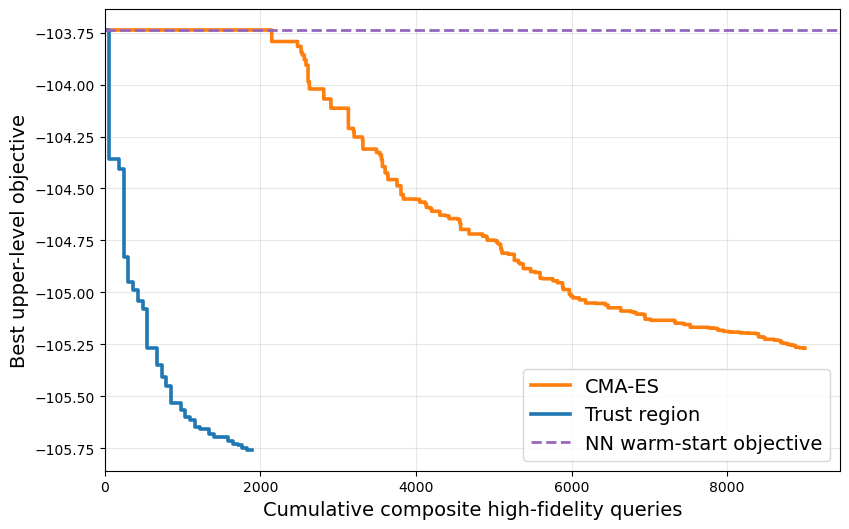

Saved: plots/trust_region_four_runs/query_convergence_000.pdf
Saved: plots/trust_region_four_runs/query_convergence_000.png


In [21]:
fig, ax = plt.subplots(figsize=FIGSIZE)
for method in ("zero", "tr"):
    curve = curves[(PLOT_RUN_LABEL, method)]
    style = METHOD_STYLE[method]
    ax.step(
        curve["queries"],
        curve["best_objective"],
        where="post",
        label=style["label"],
        color=style["color"],
        linestyle=style["linestyle"],
        linewidth=style["linewidth"],
    )

nn_style = METHOD_STYLE["nn"]
nn_objective = float(per_run.loc[PLOT_RUN_LABEL, "nn_objective"])
ax.axhline(
    nn_objective,
    label=nn_style["label"],
    color=nn_style["color"],
    linestyle=nn_style["linestyle"],
    linewidth=nn_style["linewidth"],
)

ax.set_xlim(left=0)
ax.set_xlabel(PLOT_TEXT["xlabel"], fontsize=14)
ax.set_ylabel(PLOT_TEXT["ylabel"], fontsize=14)
# ax.set_title(PLOT_TEXT["title"])
ax.grid(alpha=0.3)
ax.legend(**LEGEND_KWARGS)
fig.tight_layout()

pdf_path = OUTPUT_DIR / f"query_convergence_{PLOT_RUN_LABEL}.pdf"
png_path = OUTPUT_DIR / f"query_convergence_{PLOT_RUN_LABEL}.png"
fig.savefig(pdf_path, bbox_inches="tight")
fig.savefig(png_path, dpi=DPI, bbox_inches="tight")
plt.show()

print("Saved:", pdf_path)
print("Saved:", png_path)
